# Análisis visual de aciertos y errores en la detección de anomalías

Objetivo

Analizar cualitativamente las predicciones de los tres modelos sobre el conjunto de test oficial, identificando detecciones correctas, falsos positivos, anomalías no detectadas y errores de localización, con el fin de interpretar sus fortalezas y limitaciones

El notebook utiliza los CSV de predicciones y las visualizaciones de cuatro paneles generadas previamente mediante scripts/visualize_predictions.py

No realiza nuevos entrenamientos ni evaluaciones, modifica modelos o recalibra umbrales. El análisis se limita a interpretar la evidencia experimental existente

El análisis visual comprende cuatro categorías de MVTec AD: bottle, tile, wood y carpet

Las visualizaciones permiten examinar errores y patrones de comportamiento, pero no constituyen evidencia suficiente para generalizar conclusiones al conjunto completo ni se utilizan para ajustar o seleccionar modelos

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "results").exists() and (PROJECT_ROOT.parent / "results").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURE_ROOT = PROJECT_ROOT / "results" / "figures" / "test_examples"
MODELS = ["autoencoder", "patchcore", "dual_unet"]
DISPLAY_NAMES = {"autoencoder": "Autoencoder", "patchcore": "PatchCore", "dual_unet": "Doble U-Net"}

csv_files = sorted(FIGURE_ROOT.glob("*/**/image_predictions.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No se encontraron CSV en {FIGURE_ROOT}. "
        "Ejecuta scripts/visualize_predictions.py o copia sus resultados a esa ruta."
    )

frames = []
for csv_path in csv_files:
    frame = pd.read_csv(csv_path)
    frame["figure_path"] = frame["figure"].apply(
        lambda value: str(csv_path.parent / str(value)) if pd.notna(value) and str(value).strip() else None
    )
    frame["image_id"] = frame["path"].apply(lambda value: "/".join(Path(value).parts[-4:]))
    frames.append(frame)

predictions = pd.concat(frames, ignore_index=True)
predictions["figure_exists"] = predictions["figure_path"].apply(
    lambda path: isinstance(path, (str, Path)) and bool(str(path).strip()) and Path(path).is_file()
)
categories = sorted(predictions["category"].unique())
print(f"Categorías: {', '.join(categories)}")
print(f"Modelos: {predictions['model'].nunique()}; predicciones: {len(predictions):,}")
print(f"Figuras disponibles: {predictions['figure_exists'].sum()}")

coverage = (predictions.groupby(["category", "model"], as_index=False)
            .agg(images=("image_id", "nunique"), figures=("figure_exists", "sum")))
display(coverage)

Categorías: bottle, carpet, tile, wood
Modelos: 3; predicciones: 1,188
Figuras disponibles: 95


,category,model,images,figures
0,bottle,autoencoder,83,8
1,bottle,dual_unet,83,6
2,bottle,patchcore,83,4
3,carpet,autoencoder,117,6
4,carpet,dual_unet,117,12
5,carpet,patchcore,117,6
6,tile,autoencoder,117,6
7,tile,dual_unet,117,10
8,tile,patchcore,117,8
9,wood,autoencoder,79,9


case,category,model,Verdadero positivo,Falso positivo,Falso negativo,Verdadero negativo
0,bottle,autoencoder,41,3,22,17
1,bottle,dual_unet,48,0,15,20
2,bottle,patchcore,63,0,0,20
3,carpet,autoencoder,89,28,0,0
4,carpet,dual_unet,79,15,10,13
5,carpet,patchcore,89,28,0,0
6,tile,autoencoder,84,33,0,0
7,tile,dual_unet,60,1,24,32
8,tile,patchcore,84,31,0,2
9,wood,autoencoder,58,18,2,1


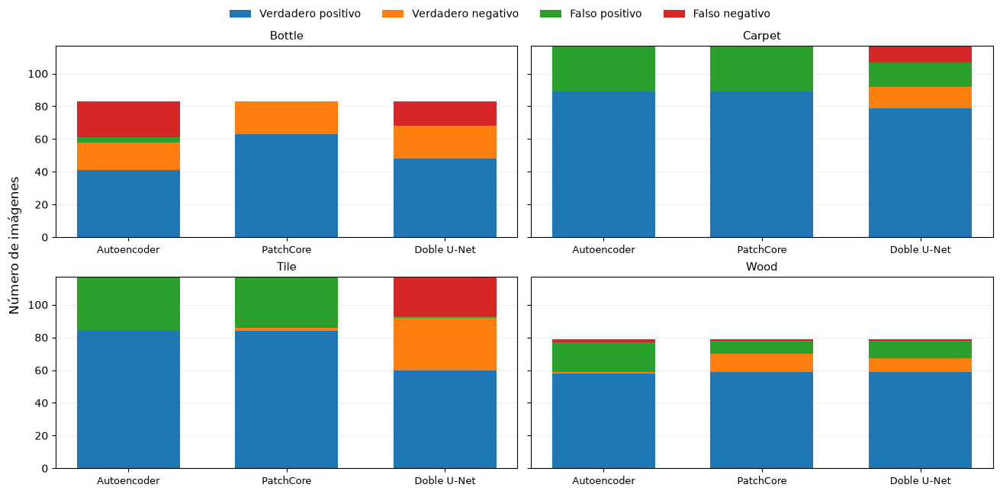

**Interpretación de bottle.** **Autoencoder:** 3 falsas alarmas y 22 anomalías omitidas; **PatchCore:** 0 falsas alarmas y 0 anomalías omitidas; **Doble U-Net:** 0 falsas alarmas y 15 anomalías omitidas.

**Interpretación de carpet.** **Autoencoder:** 28 falsas alarmas y 0 anomalías omitidas; **PatchCore:** 28 falsas alarmas y 0 anomalías omitidas; **Doble U-Net:** 15 falsas alarmas y 10 anomalías omitidas.

**Interpretación de tile.** **Autoencoder:** 33 falsas alarmas y 0 anomalías omitidas; **PatchCore:** 31 falsas alarmas y 0 anomalías omitidas; **Doble U-Net:** 1 falsas alarmas y 24 anomalías omitidas.

**Interpretación de wood.** **Autoencoder:** 18 falsas alarmas y 2 anomalías omitidas; **PatchCore:** 8 falsas alarmas y 1 anomalías omitidas; **Doble U-Net:** 11 falsas alarmas y 1 anomalías omitidas.

In [2]:
CASE_NAMES = {
    "tp": "Verdadero positivo",
    "fp": "Falso positivo",
    "fn": "Falso negativo",
    "tn": "Verdadero negativo",
}

CASE_ORDER = ["tp", "tn", "fp", "fn"]

counts = (
    predictions.groupby(["category", "model", "case"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["tp", "fp", "fn", "tn"], fill_value=0)
    .reset_index()
)

display(counts.rename(columns=CASE_NAMES))

# Cuadrícula dinámica
ncols = 2
nrows = int(np.ceil(len(categories) / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(13, 3.2 * nrows),
    sharey=True,
    constrained_layout=True,
)

axes = np.atleast_1d(axes).ravel()

for ax, category in zip(axes, categories):
    current = (
        counts[counts["category"] == category]
        .set_index("model")
        .reindex(MODELS)
        .fillna(0)
    )

    x = np.arange(len(MODELS))
    bottom = np.zeros(len(MODELS))

    for case in CASE_ORDER:
        values = current[case].to_numpy(dtype=int)

        ax.bar(
            x,
            values,
            bottom=bottom,
            label=CASE_NAMES[case],
            width=0.65,
        )
        bottom += values

    ax.set_title(category.capitalize(), fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(
        [DISPLAY_NAMES[m] for m in MODELS],
        fontsize=9,
    )
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

# Eliminar ejes sobrantes
for ax in axes[len(categories):]:
    ax.remove()

fig.supylabel("Número de imágenes")

# Leyenda compartida
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="outside upper center",
    ncol=4,
    frameon=False,
)

plt.show()

# Interpretaciones
for category in categories:
    current = (
        counts[counts["category"] == category]
        .set_index("model")
        .reindex(MODELS)
        .fillna(0)
    )

    lines = [
        f"**{DISPLAY_NAMES[model]}:** "
        f"{int(current.loc[model, 'fp'])} falsas alarmas y "
        f"{int(current.loc[model, 'fn'])} anomalías omitidas"
        for model in MODELS
    ]

    display(
        Markdown(
            f"**Interpretación de {category}.** "
            + "; ".join(lines) + "."
        )
    )

## Caso bottle

Se analiza la categoría bottle para comparar el desempeño de los tres modelos e ilustrar un caso de detección exitosa de PatchCore. El análisis utiliza exclusivamente las visualizaciones generadas previamente, sin realizar nuevas predicciones

PatchCore obtuvo el mejor resultado, sin falsas alarmas ni anomalías omitidas. En contraste, Autoencoder registró 3 falsas alarmas y 22 anomalías omitidas, mientras que Doble U-Net no presentó falsas alarmas, pero omitió 15 anomalías

Estos resultados evidencian una mayor capacidad de detección de PatchCore en esta categoría, aunque no permiten establecer por sí solos la precisión de la localización de los defectos

**Autoencoder — Verdadero positivo** | `bottle/test/contamination/002.png` | Dice: 0.002

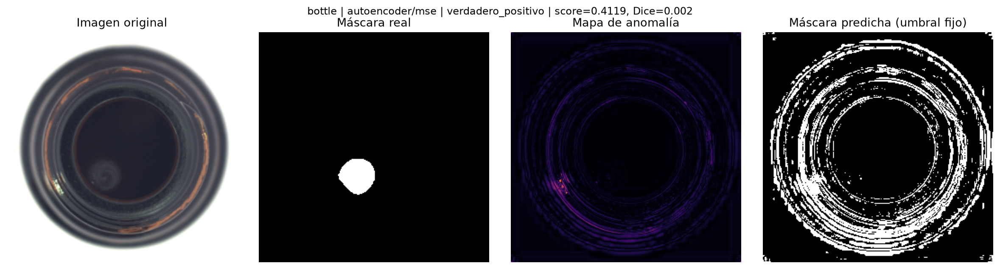

**PatchCore — Verdadero positivo** | `bottle/test/contamination/001.png` | Dice: 0.000

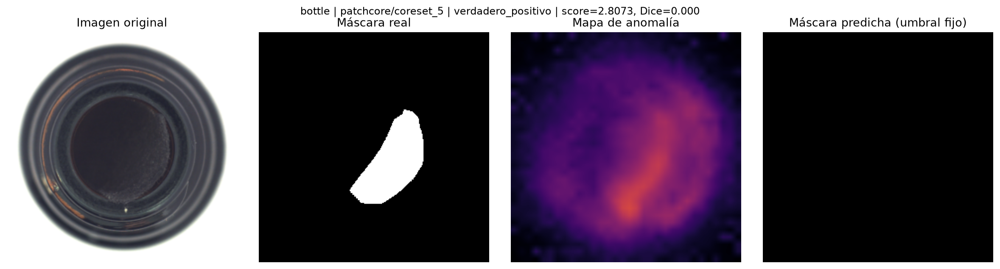

**Doble U-Net — Verdadero positivo** | `bottle/test/broken_large/007.png` | Dice: 0.140

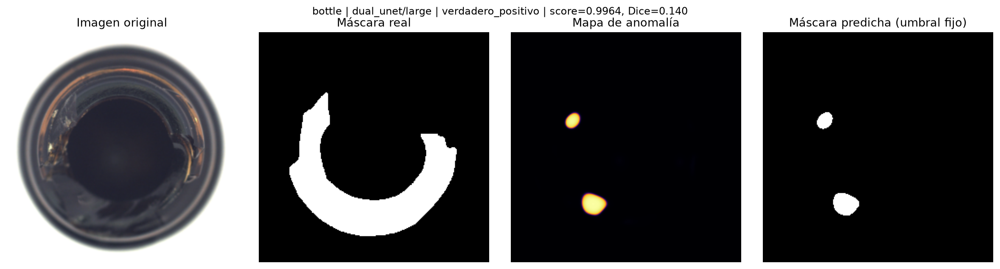

**Autoencoder:** VP=41, FP=3, FN=22, VN=17.

**PatchCore:** VP=63, FP=0, FN=0, VN=20.

**Doble U-Net:** VP=48, FP=0, FN=15, VN=20.

In [3]:
def show_saved_examples(category, model, case, max_examples=2):
    selection = predictions[
        (predictions["category"] == category)
        & (predictions["model"] == model)
        & (predictions["case"] == case)
        & (predictions["figure_exists"])
    ].sort_values(["dice", "image_id"], na_position="last").head(max_examples)
    if selection.empty:
        display(Markdown(f"*No hay figuras exportadas para {category} / {model} / {case}.*"))
        return
    for _, item in selection.iterrows():
        display(Markdown(
            f"**{DISPLAY_NAMES[model]} — {CASE_NAMES[case]}** | "
            f"`{item['image_id']}` | Dice: "
            f"{item['dice']:.3f}" if pd.notna(item["dice"]) else
            f"**{DISPLAY_NAMES[model]} — {CASE_NAMES[case]}** | `{item['image_id']}`"
        ))
        display(Image(filename=item["figure_path"], width=970))

if "bottle" in categories:
    for model in MODELS:
        show_saved_examples("bottle", model, "tp", 1)
    bottle = counts[counts.category == "bottle"].set_index("model")
    for model in MODELS:
        r = bottle.loc[model]
        display(Markdown(f"**{DISPLAY_NAMES[model]}:** VP={r['tp']}, FP={r['fp']}, FN={r['fn']}, VN={r['tn']}."))

## Falsos positivos: tile y carpet

Se analizan ejemplos de falsas alarmas en las categorías tile y carpet, correspondientes a imágenes normales clasificadas erróneamente como defectuosas

En inspección industrial, estos errores pueden generar revisiones innecesarias, aumentar los costos operativos y provocar el rechazo de piezas conformes. Las visualizaciones permiten examinar los patrones que podrían explicar estas predicciones incorrectas

### tile

**Autoencoder — Falso positivo** | `tile/test/good/009.png` | Dice: 0.000

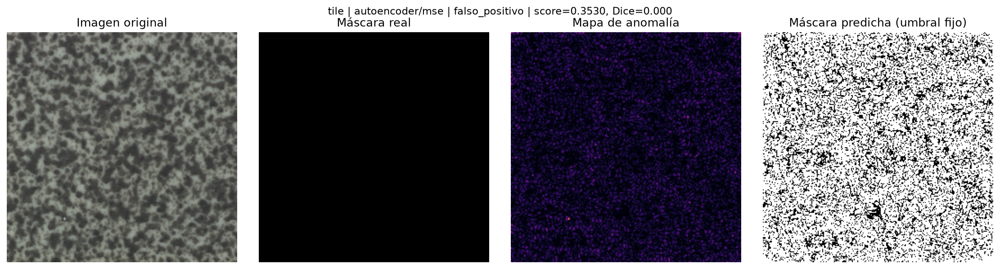

**PatchCore — Falso positivo** | `tile/test/good/014.png` | Dice: 0.000

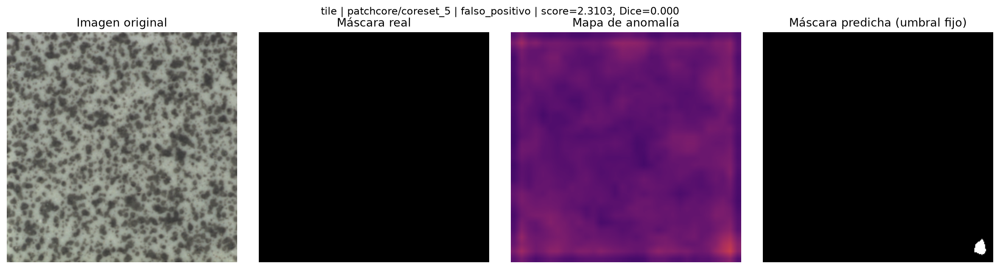

**Doble U-Net — Falso positivo** | `tile/test/good/009.png` | Dice: 0.000

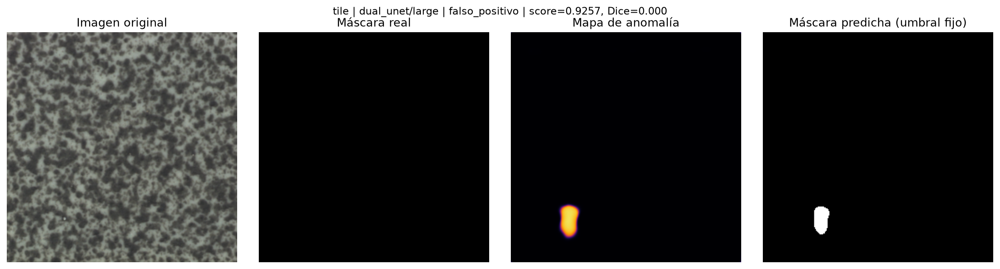

**Resultado y conclusión.** Autoencoder: 33 FP; PatchCore: 31 FP; Doble U-Net: 1 FP. Un mapa activado sobre una imagen normal constituye una falsa alarma a nivel de imagen; la inspección de las figuras permite describir su distribución espacial, pero no probar su causa visual sin análisis adicional.

### carpet

**Autoencoder — Falso positivo** | `carpet/test/good/002.png` | Dice: 0.000

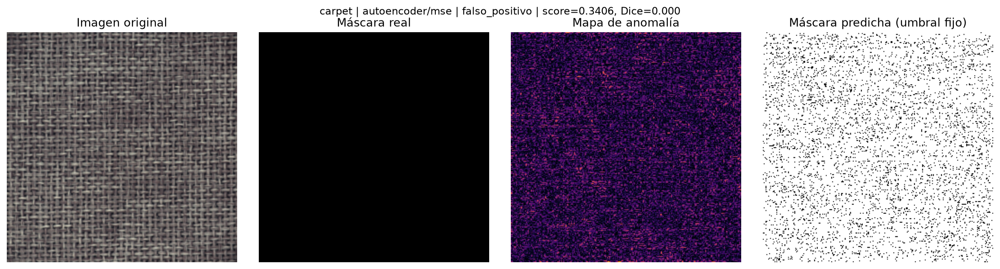

**PatchCore — Falso positivo** | `carpet/test/good/009.png` | Dice: 1.000

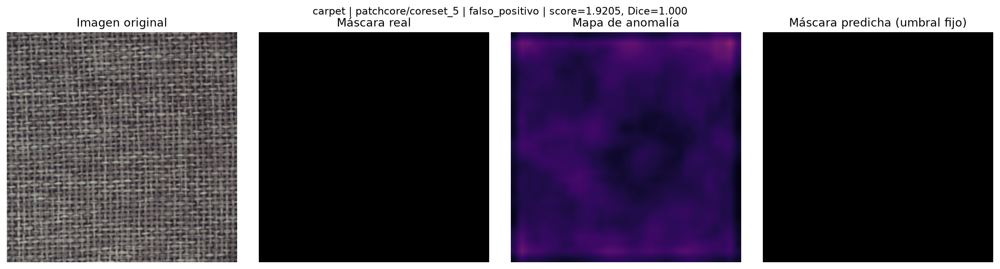

**Doble U-Net — Falso positivo** | `carpet/test/good/005.png` | Dice: 0.000

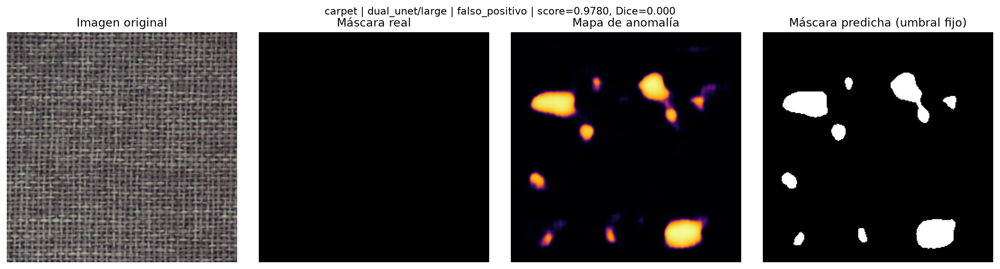

**Resultado y conclusión.** Autoencoder: 28 FP; PatchCore: 28 FP; Doble U-Net: 15 FP. Un mapa activado sobre una imagen normal constituye una falsa alarma a nivel de imagen; la inspección de las figuras permite describir su distribución espacial, pero no probar su causa visual sin análisis adicional.

In [4]:
for category in ["tile", "carpet"]:
    if category not in categories:
        continue
    display(Markdown(f"### {category}"))

    for model in MODELS:
        show_saved_examples(category, model, "fp", 1)

    rows = counts[counts.category == category].set_index("model")
    observations = [f"{DISPLAY_NAMES[m]}: {int(rows.loc[m, 'fp'])} FP" for m in MODELS]

    display(Markdown("**Resultado y conclusión.** " + "; ".join(observations)
        + ". Un mapa activado sobre una imagen normal constituye una falsa alarma a nivel de imagen; "
          "la inspección de las figuras permite describir su distribución espacial, pero no probar su causa visual sin análisis adicional."))

## Falsos negativos: defectos omitidos

Se analizan imágenes defectuosas clasificadas erróneamente como normales, un tipo de error crítico en inspección industrial porque permite que piezas defectuosas pasen inadvertidas

El análisis distingue entre una respuesta débil en el mapa de anomalías y una puntuación de detección inferior al umbral establecido. Esta diferenciación permite interpretar las posibles causas del error sin modificar los criterios de clasificación

### bottle

**Autoencoder — Falso negativo** | `bottle/test/contamination/020.png` | Dice: 0.060

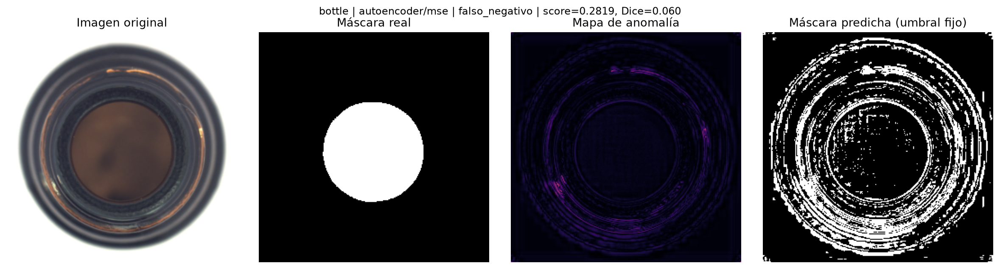

*No hay figuras exportadas para bottle / patchcore / fn.*

**Doble U-Net — Falso negativo** | `bottle/test/contamination/014.png` | Dice: 0.000

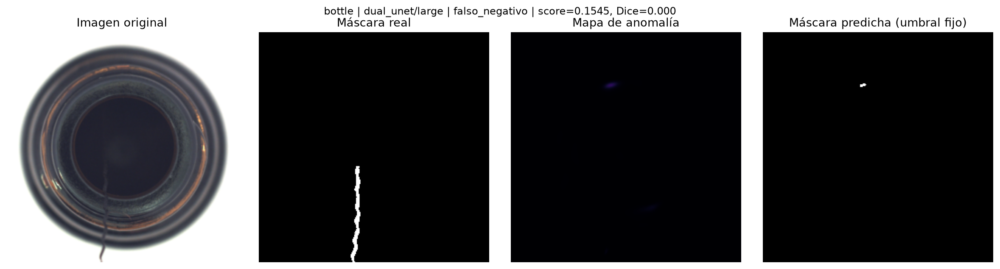

### tile

*No hay figuras exportadas para tile / autoencoder / fn.*

*No hay figuras exportadas para tile / patchcore / fn.*

**Doble U-Net — Falso negativo** | `tile/test/gray_stroke/005.png` | Dice: 0.000

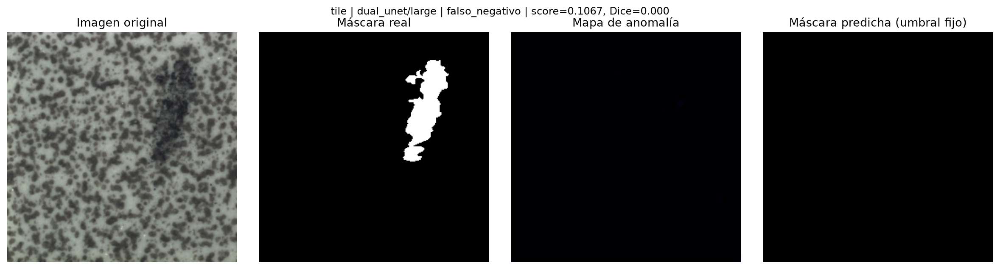

### wood

**Autoencoder — Falso negativo** | `wood/test/scratch/015.png` | Dice: 0.063

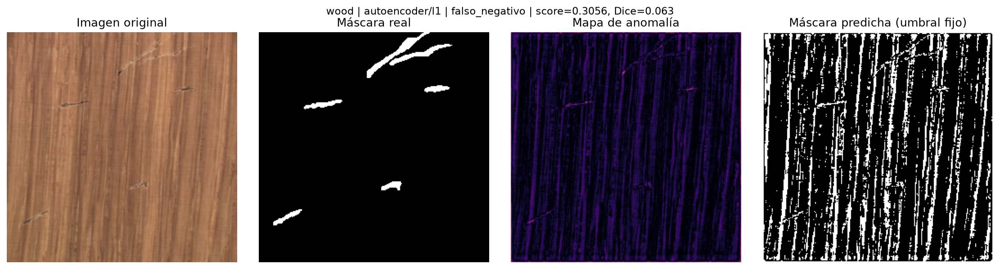

**PatchCore — Falso negativo** | `wood/test/scratch/001.png` | Dice: 0.000

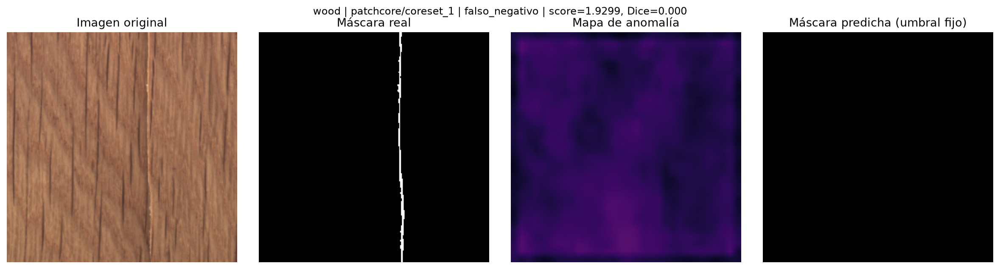

**Doble U-Net — Falso negativo** | `wood/test/scratch/018.png` | Dice: 0.000

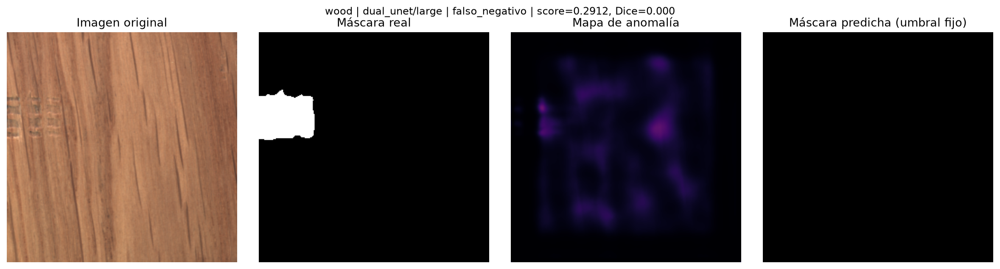

### carpet

*No hay figuras exportadas para carpet / autoencoder / fn.*

*No hay figuras exportadas para carpet / patchcore / fn.*

**Doble U-Net — Falso negativo** | `carpet/test/color/006.png` | Dice: 0.000

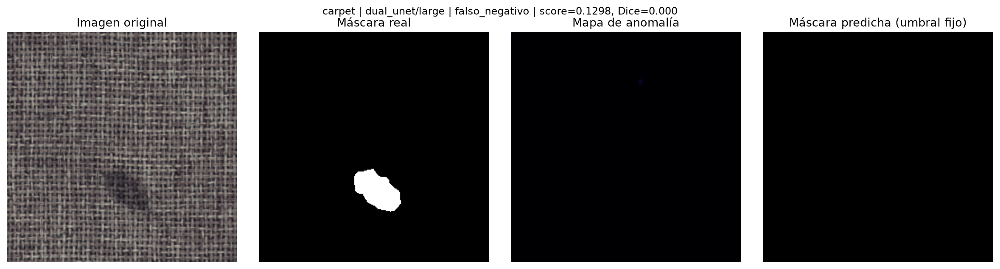

In [5]:
for category in ["bottle", "tile", "wood", "carpet"]:
    if category not in categories:
        continue

    existing = predictions[(predictions.category == category) & (predictions.case == "fn") & predictions.figure_exists]

    if existing.empty:
        continue
    
    display(Markdown(f"### {category}"))
    
    for model in MODELS:
        show_saved_examples(category, model, "fn", 1)

    subset = counts[counts.category == category].set_index("model")
    msg = "; ".join(f"{DISPLAY_NAMES[m]}: {int(subset.loc[m, 'fn'])} FN" for m in MODELS)

## Errores de localización en detecciones correctas

Se analizan imágenes defectuosas correctamente clasificadas como anómalas, pero cuyas máscaras predichas presentan un bajo solapamiento con las máscaras reales, medido mediante el coeficiente Dice

Los casos se seleccionan entre los verdaderos positivos con visualizaciones disponibles, priorizando aquellos con menor Dice. Esta selección permite identificar limitaciones en la localización de defectos

### Autoencoder

**bottle / bottle/test/contamination/002.png** — Dice = 0.0022, score = 0.4119, umbral imagen = 0.3822, umbral píxel = 0.0297.

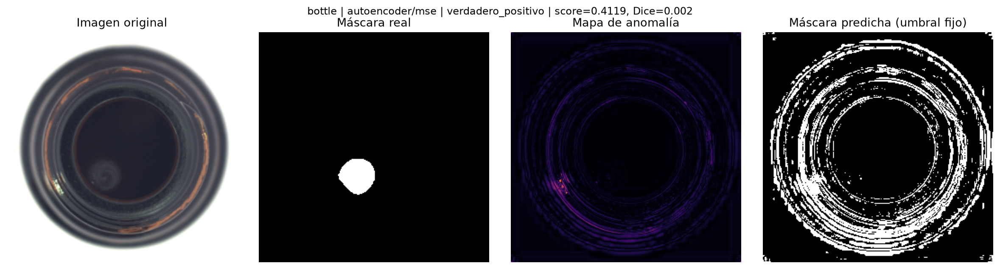

**carpet / carpet/test/metal_contamination/000.png** — Dice = 0.0036, score = 0.2516, umbral imagen = 0.2500, umbral píxel = 0.0112.

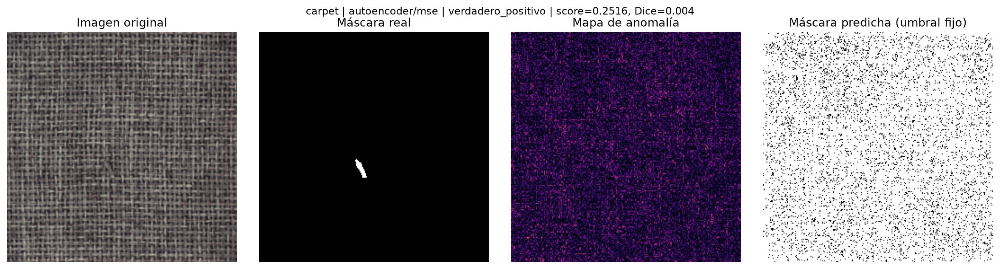

### PatchCore

**bottle / bottle/test/contamination/001.png** — Dice = 0.0000, score = 2.8073, umbral imagen = 2.2076, umbral píxel = 2.9844.

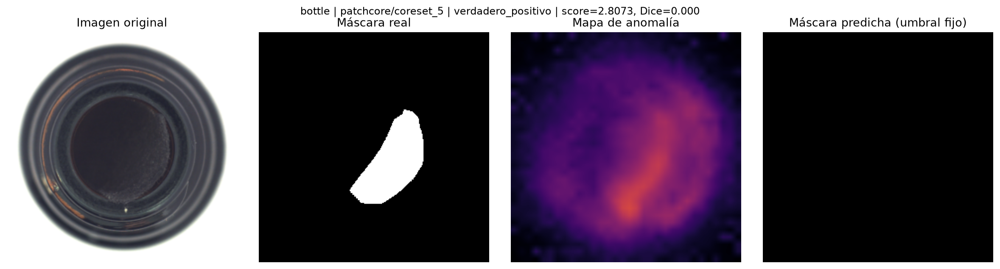

**bottle / bottle/test/contamination/003.png** — Dice = 0.0000, score = 2.2460, umbral imagen = 2.2076, umbral píxel = 2.9844.

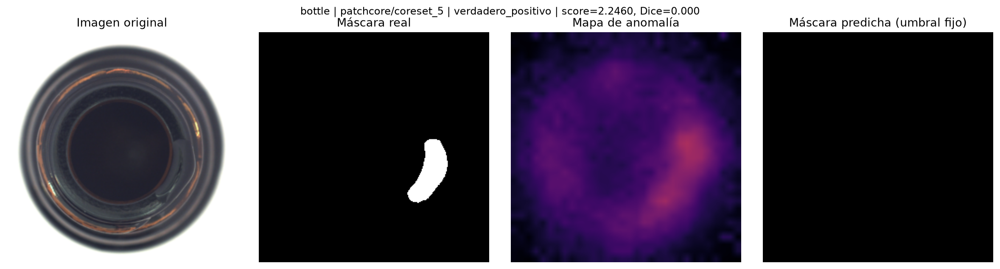

### Doble U-Net

**carpet / carpet/test/color/007.png** — Dice = 0.0000, score = 0.8912, umbral imagen = 0.8829, umbral píxel = 0.2929.

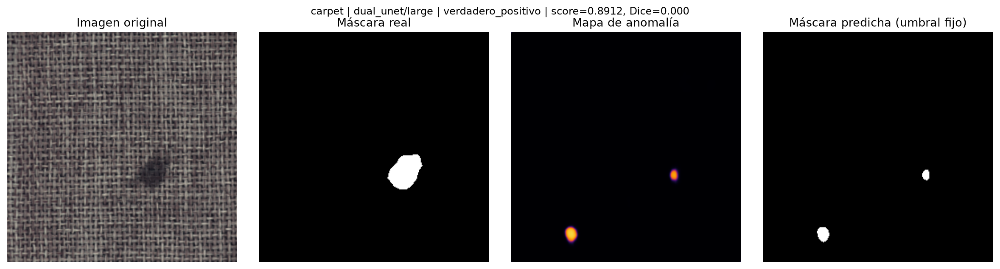

**carpet / carpet/test/color/013.png** — Dice = 0.0000, score = 0.9456, umbral imagen = 0.8829, umbral píxel = 0.2929.

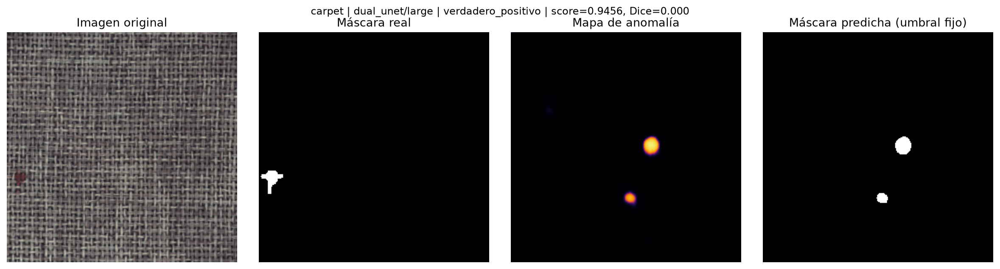

In [6]:
for model in MODELS:
    subset = predictions[
        (predictions.model == model) & (predictions.case == "tp")
        & predictions.figure_exists & predictions.dice.notna()
    ].sort_values("dice").head(2)

    display(Markdown(f"### {DISPLAY_NAMES[model]}"))
    
    if subset.empty:
        display(Markdown("*No existen ejemplos exportados de esta clase.*"))
        continue
    
    for _, item in subset.iterrows():
        display(Markdown(f"**{item['category']} / {item['image_id']}** — Dice = {item['dice']:.4f}, "
                         f"score = {item['score']:.4f}, umbral imagen = {item['image_threshold']:.4f}, "
                         f"umbral píxel = {item['pixel_threshold']:.4f}."))
        display(Image(filename=item.figure_path, width=970))
    
    low = (subset.dice < 0.2).sum()

## Comparación de modelos sobre la misma imagen

Se comparan las predicciones de los tres modelos sobre imágenes idénticas, evitando que las diferencias de contenido visual afecten la interpretación de los resultados

El análisis identifica las imágenes con visualizaciones disponibles para Autoencoder, PatchCore y Doble U-Net. Cuando no existen figuras comunes, se informa esta limitación y se presentan únicamente los resultados comparables de una misma imagen, sin combinar visualizaciones de ejemplos diferentes

### wood

**wood — misma imagen:** `wood/test/good/015.png`

,case,label,predicted_label,score,image_threshold,dice
model,,,,,,
autoencoder,fp,0,1,0.377669,0.305651,0.0
patchcore,tn,0,0,2.000483,2.008563,1.0
dual_unet,tn,0,0,0.288465,0.302243,1.0


**Autoencoder** — Falso positivo; Dice=0.000

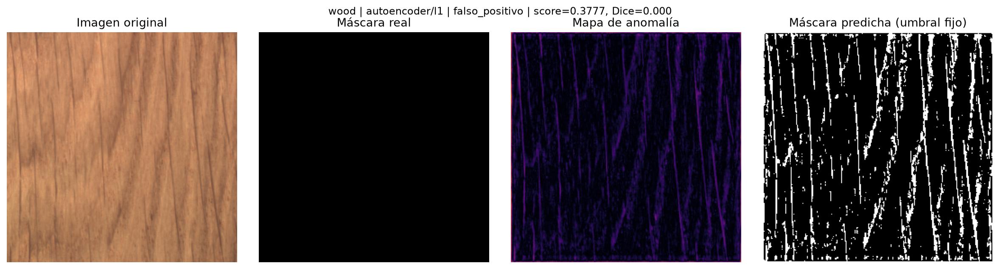

**PatchCore** — Verdadero negativo; Dice=1.000

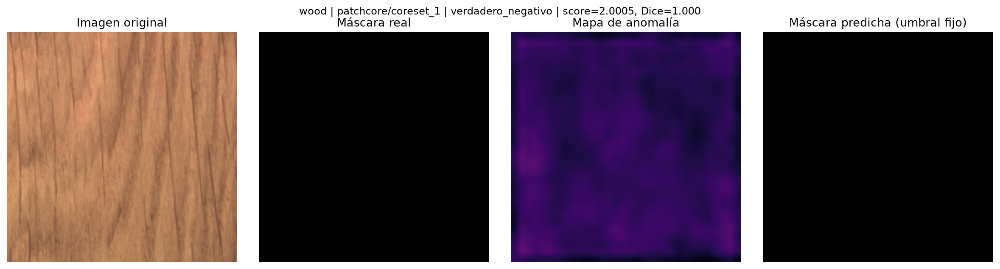

**Doble U-Net** — Verdadero negativo; Dice=1.000

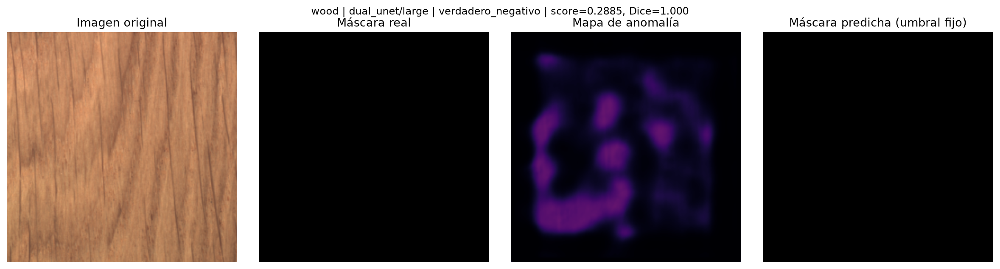

### tile

**tile — comparación numérica de la misma imagen** `tile/test/good/023.png`. No hay tres figuras correspondientes a esta imagen en el material exportado.

,case,label,predicted_label,score,image_threshold,dice
model,,,,,,
autoencoder,fp,0,1,0.245042,0.183299,0.0
patchcore,fp,0,1,2.245821,1.904251,0.0
dual_unet,tn,0,0,0.193706,0.922035,1.0


### bottle

**bottle — comparación numérica de la misma imagen** `bottle/test/contamination/009.png`. No hay tres figuras correspondientes a esta imagen en el material exportado.

,case,label,predicted_label,score,image_threshold,dice
model,,,,,,
autoencoder,fn,1,0,0.303489,0.382196,0.022206
patchcore,tp,1,1,3.890512,2.207613,0.238318
dual_unet,tp,1,1,0.990191,0.980861,0.420135


### carpet

**carpet — comparación numérica de la misma imagen** `carpet/test/good/022.png`. No hay tres figuras correspondientes a esta imagen en el material exportado.

,case,label,predicted_label,score,image_threshold,dice
model,,,,,,
autoencoder,fp,0,1,0.296760,0.249981,0.0
patchcore,fp,0,1,2.125400,1.278210,1.0
dual_unet,tn,0,0,0.738521,0.882935,0.0


In [7]:
def same_image_comparison(category):
    rows = predictions[predictions.category == category]
    
    if rows.empty:
        return
    figure_rows = rows[rows.figure_exists]
    grouped = figure_rows.groupby("image_id")["model"].nunique()
    shared_ids = grouped[grouped == len(MODELS)].index.tolist()
    
    if shared_ids:
        # Priorizamos situaciones donde los tres modelos no clasifican igual.
        disagreements = (rows[rows.image_id.isin(shared_ids)]
                         .groupby("image_id")["predicted_label"].nunique())
        shared_ids = sorted(shared_ids, key=lambda ident: (-int(disagreements.get(ident, 1)), ident))
        selected_id = shared_ids[0]
        chosen = rows[rows.image_id == selected_id].set_index("model").reindex(MODELS)
        display(Markdown(f"**{category} — misma imagen:** `{selected_id}`"))
        display(chosen[["case", "label", "predicted_label", "score", "image_threshold", "dice"]])
        
        for model in MODELS:
            row = chosen.loc[model]
            display(Markdown(f"**{DISPLAY_NAMES[model]}** — {CASE_NAMES.get(row['case'], row['case'])}; Dice={row['dice']:.3f}"))
            display(Image(filename=row.figure_path, width=970))
        return

    # Si no hay figuras comunes, elegimos misma imagen en los tres CSV sin inventar gráficos.
    pivot = rows.pivot_table(index="image_id", columns="model", values="predicted_label", aggfunc="first")
    complete = pivot.dropna(subset=MODELS)
    
    if complete.empty:
        display(Markdown(f"**{category}:** no hay identificadores comunes a los tres modelos."))
        return
    distinct = complete.nunique(axis=1)
    selected_id = distinct.sort_values(ascending=False).index[0]
    chosen = rows[rows.image_id == selected_id].set_index("model").reindex(MODELS)
    
    display(Markdown(f"**{category} — comparación numérica de la misma imagen** `{selected_id}`. "
                     "No hay tres figuras correspondientes a esta imagen en el material exportado."))
    display(chosen[["case", "label", "predicted_label", "score", "image_threshold", "dice"]])

for category in ["wood", "tile", "bottle", "carpet"]:
    if category in categories:
        display(Markdown(f"### {category}"))
        same_image_comparison(category)

## Comparación de resultados por categoría

* bottle: Doble U-Net y PatchCore registraron 0 falsos positivos, mientras que PatchCore obtuvo el menor número de falsos negativos (0), destacándose por su capacidad de detección en esta categoría.
* carpet: Doble U-Net presentó menos falsos positivos (15), mientras que Autoencoder evitó completamente los falsos negativos (0).
* tile: Doble U-Net registró el menor número de falsos positivos (1), mientras que Autoencoder obtuvo el mejor resultado en falsos negativos (0).
* wood: PatchCore presentó menos falsos positivos (8), mientras que Doble U-Net registró menos falsos negativos (1).


## Conclusión general

El análisis visual identifica tres limitaciones relevantes: falsas alarmas, anomalías omitidas y localización imprecisa de defectos correctamente detectados

La selección final del modelo se fundamenta en la evaluación cuantitativa presentada en el notebook 05. Los ejemplos visuales se utilizan exclusivamente para interpretar sus resultados y limitaciones